## Run 1: dwell position spacing = 1 mm

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "/Users/seanmullane/Desktop/Research_2025/modulated_shielding")

# Add functionality to parse folders
import os

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [2]:
## Define basic optimization parameters ##
# These parameters from Alterovitz et al. (2006) - for dose to prostate surface 
D_min = 9.5 # Gy
D_max = 15 # Gy
M_l = 100 # penalty/Gy
M_u = 100 # penalty/Gy

num_dose_points = 8
num_dwell_pos = 51

# Unpack the dose rate matrix from the locally stored file
D = np.load("D_1mmSpacing_1e5.npy")
#print(D)

In [3]:
# Construct the bounds A_ub and b_ub
# Step 1 - construct A matrix for dwell time vector (size 2r x c)
A_t = np.vstack((-M_l*D[0,:], M_u*D[0,:]))
for j in range(1, num_dose_points):
    A_t = np.vstack((A_t, -M_l*D[j,:], M_u*D[j,:]))
#print(A_t)

# Step 2 - construct A matrix for dose point vector (size 2r x r)
A_w = -1*np.identity(num_dose_points)
for j in range(0, num_dose_points):
    A_w = np.insert(A_w, 2*j, A_w[2*j,:], axis=0)
#print(A_w)

# Step 3 - combine to create A_ub
A_ub = np.hstack((A_t, A_w))
#print(A_ub)

# Step 4 - construct b_ub
b_ub = np.reshape(np.full((num_dose_points,2), [-M_l*D_min, M_u*D_max]), 2*num_dose_points)
#print(b_ub)

In [4]:
# Construct the parameter vector c
# Number of 0 entries = number of dwell positions
# Number of 1 entries = number of dose points
c = np.concatenate((np.zeros(num_dwell_pos), np.ones(num_dose_points)))
print(c)

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1.]


In [5]:
# Set up the optimization
from scipy.optimize import linprog
res = linprog(c, A_ub=A_ub, b_ub=b_ub)
print(res.fun)
#print(res.x)
print(res.x[0:num_dwell_pos])
print(res.x[num_dwell_pos:])
res.message

0.0
[15026.30672539     0.         16156.60949597     0.
     0.             0.             0.             0.
  4717.93512226     0.             0.             0.
     0.             0.             0.             0.
     0.             0.             0.             0.
     0.             0.             0.             0.
     0.             0.             0.             0.
     0.             0.             0.             0.
  3390.45832363     0.             0.             0.
     0.             0.             0.             0.
     0.             0.             0.             0.
     0.             0.             0.          6727.23842923
     0.             0.             0.        ]
[0. 0. 0. 0. 0. 0. 0. 0.]


'Optimization terminated successfully. (HiGHS Status 7: Optimal)'

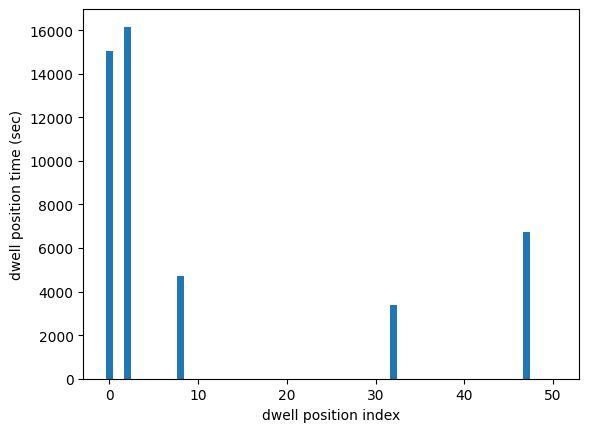

In [6]:
# Plot dwell time vs dwell position index
dwell_pos_index = np.arange(num_dwell_pos)
dwell_pos_time = res.x[0:num_dwell_pos]
# Save dwell position times for portability to another sheet
np.save("dwell_pos_time_1mm.npy", dwell_pos_time)

fig1, ax1 = plt.subplots()
ax1.bar(dwell_pos_index, dwell_pos_time)
ax1.set_xlabel('dwell position index')
ax1.set_ylabel('dwell position time (sec)')
plt.show()

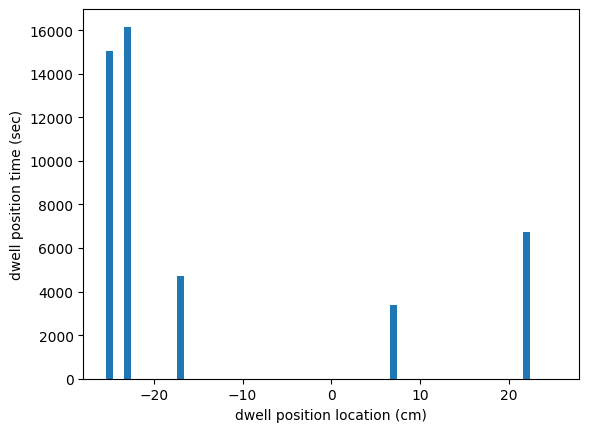

In [7]:
# Plot dwell time vs dwell position in cm
dwell_cm = np.array([x for x in np.arange(-25, 26, 1)])
fig2, ax2 = plt.subplots()
ax2.bar(dwell_cm, dwell_pos_time)
ax2.set_xlabel('dwell position location (cm)')
ax2.set_ylabel('dwell position time (sec)')
plt.show()